## Agenda

In this lecture we open the hood of a CNN. We build one **from scratch** using only PyTorch tensor operations (no `nn.Conv2d`, no autograd for the layers) and see exactly how:

- **forward propagation** turns an image into class probabilities, and
- **backward propagation** turns the loss into gradients and updates every layer,

to classify MNIST digits **0 vs 1**. Each layer is a small class with a `forward()` and a `backward()`; we also **verify our hand-written gradients against PyTorch's autograd**.

## Class Plan (120 minutes)

| # | Block | Time | Cumulative |
|---|-------|------|-----------|
| 1 | Goal, MNIST, imports, model overview | 8 min | 0–8 |
| 2 | `Layer` abstraction + correlation/convolution helpers | 12 min | 8–20 |
| 3 | Convolutional layer: forward pass | 10 min | 20–30 |
| 4 | Convolutional layer: backward pass, gradient check, Quiz 1 | 20 min | 30–50 |
| 5 | **Break** | 5 min | 50–55 |
| 6 | Activations: ReLU, TanH, Softmax | 12 min | 55–67 |
| 7 | MaxPool forward/backward + Quiz 2 | 10 min | 67–77 |
| 8 | Reshape, Dense layer, Quiz 3 | 8 min | 77–85 |
| 9 | Loss function | 6 min | 85–91 |
| 10 | Build the network, train, evaluate | 15 min | 91–106 |
| 11 | Visualize layer outputs and shapes, wrap-up, exercise | 9 min | 106–115 |
| – | Buffer | 5 min | 115–120 |


### About MNIST dataset:


- MNIST is a dataset consisting of 70,000 black-and-white images of handwritten digits.
- Each image is 28 x 28 (= 784) pixels.
- Total of 10 classes (numbers from 0 to 9)
- Each pixel is encoded as an integer from 0 (black) to 255 (white):
  - the lower the pixel value, the darker the color.   
  - 60,000 images are used as train set and 10,000 as test set.


  <center>  <img src='https://drive.google.com/uc?id=1zLPt6sTQ1HGn3q1jywjOrJs-73QO2BYY' height=230></center>

In [ ]:
import random
import time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

torch.manual_seed(0)
random.seed(0)

## Overview of CNN Model :
   - That we are going to build from Scratch

<center>  <img src='https://drive.google.com/uc?id=1Tttc9HtqZwfHsFYWDUdhH0pUpxp7J_AK' height=500></center>

Defining our base class `Layer`, which specifies the default layer properties inherited by our Convolutional, Reshape, MaxPool, Dense and activation classes.<br>
The `Layer` class has two methods:
* `forward`: takes in the input to the layer and returns the output
* `backward`: takes in the gradient of the loss with respect to the layer's **output** (`output_gradient`), updates the layer's parameters (if it has any) and returns the gradient with respect to the layer's **input**, which is handed to the previous layer

In [ ]:
class Layer:
    def __init__(self):
        self.input = None
        self.output = None

    def forward(self, input):
        raise NotImplementedError

    def backward(self, output_gradient, learning_rate):
        raise NotImplementedError

## Forward propagation in CNN

- Forward propagation is simply feeding the data in the forward direction to the model or neural network.
- Like in our case, each of our training images is processed through the-
  - convolution, activation, pooling, reshape, Dense layers.

### Helpers: cross-correlation and convolution

Our Convolutional layer needs two 2D operations:
- a **"valid" cross-correlation** (no padding; output shrinks by `kernel_size - 1`): used in the forward pass and for the kernel gradient;
- a **"full" convolution** (kernel flipped by 180°, input zero-padded so every partial overlap is counted): used for the input gradient.

*(Deep learning libraries call the first operation "convolution" even though it is strictly cross-correlation: the kernel is not flipped. Since kernels are learned, it doesn't matter.)*

**Step 1 — the slow, readable version:** slide the kernel over the image with two loops and take "multiply element by element, then sum" at each position.

In [ ]:
def correlate2d_valid_loop(a, k):
    kh, kw = k.shape
    oh, ow = a.shape[0] - kh + 1, a.shape[1] - kw + 1
    out = torch.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            out[i, j] = torch.sum(a[i:i + kh, j:j + kw] * k)
    return out

**Step 2 — the same thing without Python loops.** `unfold` gives us *all* sliding windows at once as a tensor of shape (out_h, out_w, kh, kw). Multiplying by the kernel and summing over the last two dimensions is exactly the same "multiply and sum" for every position simultaneously. This is ~100× faster, which matters because we will run it thousands of times during training.

In [ ]:
def correlate2d_valid(a, k):
    kh, kw = k.shape
    windows = a.unfold(0, kh, 1).unfold(1, kw, 1)      # (out_h, out_w, kh, kw): every window of the image
    return (windows * k).sum(dim=(-2, -1))             # multiply by the kernel and sum, for all windows at once

# Sanity check: both versions agree
a, k = torch.rand(8, 8), torch.randn(3, 3)
print("Fast == loop version:", torch.allclose(correlate2d_valid(a, k), correlate2d_valid_loop(a, k), atol=1e-5))

Fast == loop version: True


**Step 3 — "full" convolution:** flip the kernel, pad the input with `kernel_size - 1` zeros on every side, then do a valid cross-correlation.

In [ ]:
def convolve2d_full(a, k):
    kh, kw = k.shape
    k_flipped = torch.flip(k, dims=(0, 1))               # rotate the kernel by 180 degrees
    a_padded = F.pad(a, (kw - 1, kw - 1, kh - 1, kh - 1))  # pad (left, right, top, bottom)
    return correlate2d_valid(a_padded, k_flipped)

print("Output of full convolution of 4x4 input with 3x3 kernel:", convolve2d_full(torch.rand(4, 4), torch.rand(3, 3)).shape)  # 6x6

Output of full convolution of 4x4 input with 3x3 kernel: torch.Size([6, 6])


### Convolutional Layer — forward pass

The `Convolutional` class takes:
- `input_shape` = (channels, height, width) of its input,
- `kernel_size`,
- `depth` = the number of kernels/filters.

**Initialization.** Each kernel has shape (input channels, k, k), so all kernels together have shape `(depth, input_depth, k, k)`. Kernel weights are random, scaled by `sqrt(2 / fan_in)` (He initialization) so activations don't explode as layers get wider. We use **one bias per filter** (initialized to 0), like `nn.Conv2d`.

The output shape is `(depth, H - k + 1, W - k + 1)` (the output-size formula with no padding, stride 1).

#### Forward propagation in Convolution layer?

- The forward function iterates through every filter in every image channel and
 - it pass over a kernel of specified size over the image and
 - perform the convolution operation between the kernels and the input image.

 <center>  <img src='https://drive.google.com/uc?id=1PPy9sjvh36qktkqeFnB-WBiNj3ZPNufU' width=500 height=190></center>
- Forward propagation mathematically for the *Convolutional Layer* is as follows:


<center>  <img src='https://drive.google.com/uc?id=1vMgkDBw6pRwdLA7J-gZ_mFG9Frytkd2Z' width=500 height=80></center>

- where Y is the output of our convolutional operation which is equal to the Bias plus the sum of cross-correlations between the input channels (Xⱼ) and our convolution kernel/filter (Kᵢⱼ), represented by * . In our implementation the bias Bᵢ is a single number per filter, added at every position.
- This equation is implemented to calculate output through every step of our convolutional operation till every image is applied the convolutional operation for the depth / number of kernels of the layer  
   
  - Expanding the equation, we get:

<center>  <img src='https://drive.google.com/uc?id=1fsFbtbIIIGfBY_3fD9itb_fwD3qGE76z' width=500 height=200 width=150></center>
where d is the depth/number of filters and n is the input depth.
<br>


- By using these equations, we pass the filters with their weights over the image matrix, to compute the output of the convolutional layer.

The forward pass uses the `correlate2d_valid()` helper: for every filter `i`, accumulate the cross-correlation of each input channel `j` with its kernel `K[i, j]`, then add the bias.

In [ ]:
class Convolutional(Layer):
    def __init__(self, input_shape, kernel_size, depth):
        input_depth, input_height, input_width = input_shape
        self.depth = depth
        self.input_shape = input_shape
        self.input_depth = input_depth
        self.output_shape = (depth, input_height - kernel_size + 1, input_width - kernel_size + 1)
        self.kernels_shape = (depth, input_depth, kernel_size, kernel_size)
        fan_in = input_depth * kernel_size * kernel_size
        self.kernels = torch.randn(*self.kernels_shape) * (2.0 / fan_in) ** 0.5   # He initialization
        self.biases = torch.zeros(depth)                                          # one bias per filter

    def forward(self, input):
        self.input = input
        self.output = torch.zeros(self.output_shape)
        for i in range(self.depth):                  # for every filter ...
            for j in range(self.input_depth):        # ... and every input channel
                self.output[i] += correlate2d_valid(self.input[j], self.kernels[i, j])
            self.output[i] += self.biases[i]         # add the filter's bias once
        return self.output

Quick test: one 28×28 grayscale image through 5 filters of size 3×3 should give a (5, 26, 26) output.

In [ ]:
test_conv = Convolutional((1, 28, 28), 3, 5)
print(test_conv.forward(torch.rand(1, 28, 28)).shape)

torch.Size([5, 26, 26])


#### How Backpropagation works in Convolution ?

Recall what is backpropagation ?
- Backward Propagation refers to updating the weights and biases of our model with respect to the loss of our model.

####In case of Convolution:

- The learnable parameters are the **kernels** and the **biases**. We also need the gradient with respect to the **input**, so it can be passed back to the previous layer.
- For updating the kernels and biases we need to compute their gradients,
- From the forwardpropagation we have the derivative of the error from which we will compute:

  - Derivative of L (error of the network) with respect to kernels (K) and biases of the layer (B)
  - Derivative of L with respect to the input (X)

<center>  <img src='https://drive.google.com/uc?id=1kqs8v_XjGAhKw26TxLyyBloHy_x-bKVt' height=350 width=575></center>


#### 1. Kernel updates:

- The Image below depicts the computation of the derivative of the Loss (L) with respect to the Kernels (K)




<center>  <img src='https://drive.google.com/uc?id=1oFv2vJeWr2_nhzVjitfs7OyQHkoCAeJr' height=350></center>

<center>  <img src='https://drive.google.com/uc?id=1XI9J7oo0a6lHHFgRumOst_WZZ6QNB7Yz' height=350 width=575></center>

<br>

#### 2. Bias updates:

Then we Calculate the derivative of L (error of the network) with respect to the bias of the layer as follows:

<center>  <img src='https://drive.google.com/uc?id=1Wj-yxhihBkzr2qk5QMojiApWY7JnWw9a' height=350 width=575></center>

- **Our implementation uses one scalar bias per filter** (like `nn.Conv2d`), added at every position of that filter's output. By the chain rule, its gradient is the **sum of the output gradient over all positions** of that filter. (The picture above shows the special case where the bias has the full output shape; there the gradient is just the output gradient itself.)

#### 3. Input updates:

- The derivative of L (error of the network) with respect to the Input of the layer as follows:

<center>  <img src='https://drive.google.com/uc?id=1iGEPp7nc1eTHY58CjVe1bzFgZBi5GzfI' height=350 width=575></center>


<center>  <img src='https://drive.google.com/uc?id=1M3CzI9KnCgJG-1_RfJK9Ya15PqH8iLDI' height=350 width=575></center>

<br><br>Now let's understand how this works<br>

<center>  <img src='https://drive.google.com/uc?id=11VhVh2zqmHXIkaUP-sZ3Bi9fryNd__CU' height=500></center>

- This depicts that the input gradient i.e. derivative of Loss w.r.t. to the input is equal to the output gradient i.e. derivative of Loss w.r.t. the output gradient fully cross-correlated (* symbol) with the 180 degress rotated kernel.

- This concludes that the input gradient is equal to the output gradient fully convolved with the kernel

### Implementing `backward()` for the Convolutional layer

Given `output_gradient` (∂L/∂Y, same shape as the output) we need three things:

| Gradient | Formula | Code idea |
|---|---|---|
| ∂L/∂K[i,j] | valid cross-correlation of **input channel j** with **output gradient i** | `correlate2d_valid(input[j], output_gradient[i])` |
| ∂L/∂B[i] | sum of output gradient i | `output_gradient[i].sum()` |
| ∂L/∂X[j] | sum over filters i of the **full convolution** of output gradient i with kernel K[i,j] | `convolve2d_full(output_gradient[i], kernels[i,j])` |

Then we do a gradient-descent step: `parameter -= learning_rate * gradient`. Here is the complete layer (the forward pass is unchanged):

In [ ]:
class Convolutional(Layer):
    def __init__(self, input_shape, kernel_size, depth):
        input_depth, input_height, input_width = input_shape
        self.depth = depth
        self.input_shape = input_shape
        self.input_depth = input_depth
        self.output_shape = (depth, input_height - kernel_size + 1, input_width - kernel_size + 1)
        self.kernels_shape = (depth, input_depth, kernel_size, kernel_size)
        fan_in = input_depth * kernel_size * kernel_size
        self.kernels = torch.randn(*self.kernels_shape) * (2.0 / fan_in) ** 0.5   # He initialization
        self.biases = torch.zeros(depth)                                          # one bias per filter

    def forward(self, input):
        self.input = input
        self.output = torch.zeros(self.output_shape)
        for i in range(self.depth):
            for j in range(self.input_depth):
                self.output[i] += correlate2d_valid(self.input[j], self.kernels[i, j])
            self.output[i] += self.biases[i]
        return self.output

    def backward(self, output_gradient, learning_rate):          # NEW
        kernels_gradient = torch.zeros(self.kernels_shape)
        input_gradient = torch.zeros(self.input_shape)

        for i in range(self.depth):
            for j in range(self.input_depth):
                # dL/dK[i,j]: correlate the input channel with the output gradient
                kernels_gradient[i, j] = correlate2d_valid(self.input[j], output_gradient[i])
                # dL/dX[j]: full convolution of the output gradient with the kernel (summed over filters)
                input_gradient[j] += convolve2d_full(output_gradient[i], self.kernels[i, j])
        biases_gradient = output_gradient.sum(dim=(1, 2))        # dL/dB[i]: sum over all positions

        # gradient-descent update
        self.kernels -= learning_rate * kernels_gradient
        self.biases -= learning_rate * biases_gradient
        return input_gradient

#### Did we get the math right? Compare with PyTorch autograd

A hand-written backward pass is easy to get subtly wrong. A **gradient check** compares our gradients with those PyTorch computes automatically for `F.conv2d`. With `learning_rate=1`, the change in the parameters equals the gradient.

In [ ]:
torch.manual_seed(1)
layer = Convolutional((2, 6, 6), 3, 4)          # 2 input channels, 3x3 kernels, 4 filters
x = torch.randn(2, 6, 6)
out = layer.forward(x)
out_grad = torch.randn_like(out)                 # pretend this came from the next layer

W0, b0 = layer.kernels.clone(), layer.biases.clone()
dx_ours = layer.backward(out_grad, learning_rate=1.0)
dW_ours, db_ours = W0 - layer.kernels, b0 - layer.biases    # = gradients because lr = 1

# the same computation with autograd
xt, Wt, bt = x.clone().requires_grad_(), W0.clone().requires_grad_(), b0.clone().requires_grad_()
yt = F.conv2d(xt[None], Wt, bt)[0]
yt.backward(out_grad)

print("forward  matches:", torch.allclose(out, yt.detach(), atol=1e-5))
print("dL/dX    matches:", torch.allclose(dx_ours, xt.grad, atol=1e-5))
print("dL/dK    matches:", torch.allclose(dW_ours, Wt.grad, atol=1e-5))
print("dL/dB    matches:", torch.allclose(db_ours, bt.grad, atol=1e-5))

forward  matches: True
dL/dX    matches: True
dL/dK    matches: True
dL/dB    matches: True


**Quiz 1** :

  1.  **How can we calculate the gradients to update Kernel weights in Convolutional Layer during Backpropagation ?**<br>

    A) Calculating derivative of image pixels with respect to kernel weights
    B) Calculating derivative of loss with respect to kernel weights
    C) Calculating the derivative of kernels with respect to bias
    D) Calculating the derivative of input with respect to loss
<br>

**Solution** :

B)

- We calculate the gradients of the loss function by computing the derivative (Loss/output) with the help of the derivative (Loss/Kernels)
$\frac{\partial Loss}{\partial {w_i}}$, derivative (Loss/Bias) $\frac{\partial Loss}{\partial {b_i}}$and derivative (Loss/Input)$\frac{\partial Loss}{\partial {X_i}}$

- We update the kernels and the biases of our convolutional layer with gradient descent: subtract `learning_rate × gradient` from each parameter

> **🤖 Ask AI (optional, 1 min):** *"Why do deep learning libraries call cross-correlation 'convolution'? Would flipping the kernel change anything for a network that learns its kernels from data?"* Then look at where our `convolve2d_full` flips the kernel — and why the **backward** pass needs a true convolution.

# ☕ Break (5 minutes)

### Activation Functions:

We have used majorly 3 activation functions (ReLU, TanH and Softmax) in our CNN model architecture which are explained below:

In **Backpropagation** of all activations, we apply the backward function of the activation on the input.

=> The gradient arriving from the next layer is multiplied **element-wise** by the derivative of the activation, evaluated at the layer's input (chain rule).

In [ ]:
class Activation(Layer):
    def __init__(self, activation, activation_prime):
        self.activation = activation               # the function
        self.activation_prime = activation_prime   # its derivative, needed for backpropagation

    def forward(self, input):
        self.input = input
        return self.activation(self.input)

    def backward(self, output_gradient, learning_rate):
        # chain rule: dL/dx = dL/dy * f'(x)   (element-wise, no parameters to update)
        return output_gradient * self.activation_prime(self.input)

#### ReLU

The ReLU activation function works on a simple principle.

- If the input value is less than zero, the output is zero

- else if the input value is greater than or equal to zero, the output is same is as input value
<br>

ReLU introduces non-linearity into our CNN. Because it zeroes out every negative activation, it produces sparse, "either active or silent" outputs and helps avoid the vanishing-gradient problems that saturating activations like sigmoid or tanh can run into.

<br>

<center>  <img src='https://drive.google.com/uc?id=1LXb4on8enumLbbv1ZOfs0mQNytPOtF3a' width=220 height=80></center><br>

During **Backpropagation**, the ReLU activation works as follows :<br> <br>
The ReLU function is defined as: <br>

<center>  <img src='https://drive.google.com/uc?id=1HyqadM9ED4XhVt-B-HGMIom8VHlOybYR' height=270></center><br>

For $x > 0$ the output is $x$, i.e. $f(x) = max(0, x)$

Derivative of $f(x)$ = $f'(x)$ : if $x < 0$, output is $0$. if $x > 0$, output is 1.

The derivative $f '(0)$ is not defined. So it's usually set to $0$.<br>

<center>  <img src='https://drive.google.com/uc?id=1-oxuuaM6wpI_kr3Dtz_Lnwp-YySI9eBn' width=220 height=80></center><br>


Code representation of the above calculation can be represented as :
<pre>def relu_prime(x):
   return torch.where(x <= 0, torch.zeros_like(x), torch.ones_like(x))</pre>

In [ ]:
class ReLU(Activation):
    def __init__(self):
        def relu(x):
            return torch.where(x > 0, x, torch.zeros_like(x))

        def relu_prime(x):
            return torch.where(x <= 0, torch.zeros_like(x), torch.ones_like(x))

        super().__init__(relu, relu_prime)

#### TanH

The TanH activation function takes any input value and outputs the value in the range -1 to 1


- The greater the input value, the closer the output value will be equal to 1


- The smaller the input, the closer the output value will be to -1

<center>  <img src='https://drive.google.com/uc?id=1MqSgrbLwMz7u3G7LowITwHDMVHeDaKok' height=240></center>

In practice, TanH is useful when we want our model to converge quickly with a larger learning rate, since it produces stronger gradients than a saturating activation like sigmoid, which tends to help training converge faster while still reaching good accuracy.

<center>  <img src='https://drive.google.com/uc?id=1eCuIjpRCGlldmP98l1Ubk1nCXiTlquFv' height=110 width=200></center>


In **Backpropagation** of TanH activation, we calculate the gradients for tanh by computing the derivative of TanH function.

Calculating the gradient for the tanh function also uses the quotient rule:

<center>  <img src='https://drive.google.com/uc?id=1tJNVaouljjOEykAD4L9aWFwsE7YNrdaf' height=240></center>

The derivative of tanh(x) is therefore `1 - torch.tanh(x) ** 2`, which we implement below using `torch.tanh`.

In [ ]:
class TanH(Activation):
    def __init__(self):
        def tanh(x):
            return torch.tanh(x)

        def tanh_prime(x):
            return 1 - torch.tanh(x) ** 2

        super().__init__(tanh, tanh_prime)

#### Softmax

the Softmax activation function is generally used as last layer in a neural network



- softmax converts the Dense layer's (classification layer) outputs to a probability map such that the sum of the outputs is equal to 1



- Softmax is used in classification problems — in our case the network has 2 output classes (digit 0 vs. digit 1)

<br>


<center>  <img src='https://drive.google.com/uc?id=17s1wV-Jl2hFMGmOIZ0Ri38Znp0Jo8aiy' height=160></center>


**Backpropagation**

During the backward pass, a softmax layer receives a gradient, the partial derivative of the loss with respect to its output values.


<br>

To use the softmax function in neural networks, we need to compute its derivative. If we define $\Sigma_C = \sum_{d=1}^C e^{z_d} \, \text{for} \; c = 1 \cdots C$ so that $y_c = e^{z_c} / \Sigma_C$, then this derivative ${\partial y_i}/{\partial z_j}$ of the output $\mathbf{y}$ of the softmax function with respect to its input $\mathbf{z}$ can be calculated as:
<br><br>

<center>  <img src='https://drive.google.com/uc?id=1hXYwgq4FyXnYK0rwG7o4FjpRYELUNZUM' height=90></center>

The first part of this expression propagates the softmax values down the diagonal, and then we subtract the product of softmax values with respect to input. In matrix form the Jacobian is `diag(y) - y yᵀ`.

*Numerical note:* `exp(z)` overflows for large `z`, so in the forward pass we first subtract `max(z)` from all inputs. This does not change the result (it cancels in the ratio) but keeps the numbers small.

In [ ]:
class Softmax(Layer):
    def forward(self, input):
        tmp = torch.exp(input - torch.max(input))       # subtract the max for numerical stability
        self.output = tmp / torch.sum(tmp)
        return self.output

    def backward(self, output_gradient, learning_rate):
        n = self.output.numel()
        # Jacobian: dy_i/dz_j = y_i * (delta_ij - y_j)
        return torch.matmul((torch.eye(n) - self.output.T) * self.output, output_gradient)

### MaxPooling Layer

The MaxPool layer selects the maximum pixel values for every image in a particular kernel area.
<br>

<center>  <img src='https://drive.google.com/uc?id=1Wv3mBlveedhmRROXun8Bd8hZVZJ5RqLo' width=400></center>

Forward propagation:

- We Select the maximum value out of a given kernel area in an Input Image, the filter slides over our image w.r.t. given stride.

<center>  <img src='https://drive.google.com/uc?id=1RliqXph1H-XNH0chWnSqZJLwqZiIQPmO' width=400></center>

Backward propagation:

- For the backward propagation, we have to select only the elements in our input matrix that were selected during the forward propagation of the maxpool layer, zeroing out all the other indices that were not selected during forward propagation.

- In other words the gradient with respect to the input of the max pooling layer will be a matrix of zeros except on the places that was selected during the forward propagation.

- If several values in a window tie for the maximum (common right after ReLU, which creates many zeros) we send the gradient to just **one** of them (the first), as PyTorch does. Otherwise the same gradient would be counted several times.

<center>  <img src='https://drive.google.com/uc?id=1D27c4xmPb7nHF5_KDXY1GveeoOs9Yy1y' width=400>

**Implementation idea (vectorized):**
- *Forward:* `unfold` gives all pooling windows; we take the max of each window **and remember which position inside the window won** (`argmax`).
- *Backward:* start from a tensor of zeros and **add** each output gradient at the remembered winning position. (We *add* because with stride < kernel size, windows overlap and one input pixel can win in several windows.)

In [ ]:
class MaxPool(Layer):
    def __init__(self, input_shape, kernel_size, stride):
        self.input_shape = input_shape
        self.input_depth, self.input_height, self.input_width = input_shape
        self.kernel_size = kernel_size
        self.stride = stride
        # MaxPool has no learnable weights (see Quiz 2), so nothing else to initialize.

    def forward(self, input):
        self.input = input
        k, s = self.kernel_size, self.stride
        # all pooling windows: (channels, out_h, out_w, k, k)  ->  flatten each window to k*k values
        windows = input.unfold(1, k, s).unfold(2, k, s)
        windows = windows.reshape(*windows.shape[:3], k * k)
        self.output, self.argmax = windows.max(dim=-1)       # max value and its position inside the window
        return self.output

    def backward(self, output_gradient, learning_rate):
        k, s = self.kernel_size, self.stride
        C, OH, OW = self.output.shape
        # absolute (row, col) of each window's winner
        channels = torch.arange(C).view(C, 1, 1).expand(C, OH, OW)
        rows = (torch.arange(OH) * s).view(1, OH, 1) + self.argmax // k
        cols = (torch.arange(OW) * s).view(1, 1, OW) + self.argmax % k
        dx = torch.zeros(self.input_shape)
        dx.index_put_((channels, rows, cols), output_gradient, accumulate=True)   # route the gradients
        return dx

Check against PyTorch's own `max_pool2d` (forward and backward) on a random input:

In [ ]:
torch.manual_seed(2)
pool = MaxPool((3, 8, 8), kernel_size=2, stride=1)
x = torch.randn(3, 8, 8)
out = pool.forward(x)
g = torch.randn_like(out)
dx = pool.backward(g, 0.0)

xt = x.clone().requires_grad_()
yt = F.max_pool2d(xt[None], kernel_size=2, stride=1)[0]
yt.backward(g)
print("forward matches :", torch.allclose(out, yt.detach()))
print("backward matches:", torch.allclose(dx, xt.grad, atol=1e-6))

forward matches : True
backward matches: True


**Quiz 2** :


**Which of the following is true about MaxPooling Layer** ?

A) MaxPooling layer does not have any trainable parameters<br>
B) MaxPooling layer helps in reducing computation<br>
C) In MaxPooling we take the highest pixel value inside the kernel window<br>
D) All of the above

Solution :<br>
D)

- MaxPooling and AveragePooling layers does not perform any learning and are only used for down-sampling the data
- Since max pooling is reducing the resolution of the given output of a convolutional layer, it reduces the amount of parameters in the network and consequently reduces computational load.
- Max pooling is a pooling operation that selects the maximum element from the region of the feature map covered by the filter.

### Reshape Layer or Flattening

- To reshape arrays inorder to pass through dense layers
- The Reshape layer is used to reshape the dimenions of an input tensor to a desired compatible shape using `torch.reshape` </br>
- For example we may reshape a tensor of size (5, 4, 1) to a size of (20, 1) using `torch.reshape`

In [ ]:
class Reshape(Layer):
    def __init__(self, input_shape, output_shape):
        self.input_shape = input_shape
        self.output_shape = output_shape

    def forward(self, input):
        return torch.reshape(input, self.output_shape)             # e.g. (5,25,25) -> (3125,1)

    def backward(self, output_gradient, learning_rate):
        return torch.reshape(output_gradient, self.input_shape)    # undo it for the gradient

### Dense Layer

### Recall from NN class ?

- The Dense layer, also known as fully-connected or linear layer does a simple job of converting the learned features from the images by the convolutional layer TO a feature vector which is used to clasify image based on output form convolutional layers.


- W=Weight matrix, X=Input Matrix, b=Bias, Z=Output matrix
<center> $Z = W.X + B$</center>

- Dense Layer is usually the "classification layer" as it classifies the feature vector that we have curated from the features that our Convolutional layer learned to classify into 2 classes

<br>


Recall from Neural Networks class, during **Backpropagation** in Dense Layer, we compute its Gradients using the following process :

- Calculate weights gradient by dot product of output gradient and transpose of input
- Calculating the input gradient by performing dot product of weights transpose and output gradient
- Updating the weights of the layer with weights gradient w.r.t. the rate = learning rate
- Updating the bias of the layer with output gradient w.r.t. rate = learning rate

<center>  <img src='https://drive.google.com/uc?id=1o_xBpQe88krbGs4Ja0czyGjSSO0VVrAI' height=200></center>

In [ ]:
class Dense(Layer):
    def __init__(self, input_size, output_size):
        self.weights = torch.randn(output_size, input_size) * (1.0 / input_size) ** 0.5   # Xavier-style scaling
        self.bias = torch.zeros(output_size, 1)

    def forward(self, input):
        self.input = input
        return torch.matmul(self.weights, self.input) + self.bias        # Z = W.X + b

    def backward(self, output_gradient, learning_rate):
        weights_gradient = torch.matmul(output_gradient, self.input.T)   # dL/dW
        input_gradient = torch.matmul(self.weights.T, output_gradient)   # dL/dX (uses the OLD weights)
        self.weights -= learning_rate * weights_gradient
        self.bias -= learning_rate * output_gradient                      # dL/db = output gradient
        return input_gradient

**Quiz 3** :

**Suppose we have a neuron with weights [-3, 2.8, -1] and bias = 0.5 input [4, 2, 2]
<br>What will be the output, when the input [4, 2, 2] is passed to a Dense Layer and its activation function is ReLU ?**
<br><br>
A) -1.9<br>
B) 7.9<br>
C) 0<br>
D) None of the above<br>

<br><br>

**Solution** :

C)

Given $W_1 = -3$, $W_2 = 2.8$ and $W_3 = -1$, <br>
$X_1 = 4$, $X_2 = 2$ and $X_3 = 2$ and $b = 0.5$

To compute the output of a Dense layer, we have the formula $W^T.X + b$ <br>
which translates to (($W_1^T.X_1$) + ($W_2^T.X_2$) + ($W_3^T.X_3)) +  b$ <br><br>
Equating value of W, X and b in our eqn. we get :     
= ((-3).(4) + (2.8).(2) + (-1).(2)) + 0.5<br>
= (-12 + 5.6 - 2) + 0.5<br>
= -8.4 + 0.5<br>
= -7.9

ReLU zeroes out (output = 0) any input value that is less than 0. Since -7.9 < 0,
therefore, the answer is 0

### Defining the Log Loss



Log-loss is the negative mean of the log of correctly predicted probabilities for each step.

Log-loss is depicts how close the prediction probability is to the corresponding true value. The more the predicted probability diverges from the actual value, the higher is the log-loss value.
<br>
<center>  <img src='https://drive.google.com/uc?id=1aSE-x2hoiNzY0MY00HrfvYLUkSPqgCKc' width=500 height=90></center>

We calculate log loss by taking the mean of the log of the true predicted probabilties for each step in every epoch.
<br>
- During **backpropagating** through our network, we need to calculate the gradients of our network to update them.
- For Calculating the gradients of our network, we use the derivative of log loss with respect to the output, to calculate the loss between the output and the actual labels.
<center>  <img src='https://drive.google.com/uc?id=1Hh5dnx58DrM1iILiYpQEWClIH7Q7_Qrq'  height=300></center>

Since our network ends in a Softmax with two outputs and the target is one-hot, we apply this binary log loss to each of the two outputs and average them. We also **clip** predictions to [ε, 1−ε] so that `log(0)` can never produce `inf`/`nan`.

the derivative of log loss is $1/N *((1 - ytrue) / (1 - ypred) - ytrue / ypred)$ which we have coded as :

`((1 - y_true) / (1 - y_pred) - y_true / y_pred) / torch.numel(y_true)`

In [ ]:
EPS = 1e-7

def log_loss(y_true, y_pred):
    y_pred = y_pred.clamp(EPS, 1 - EPS)        # avoid log(0)
    return torch.mean(-y_true * torch.log(y_pred) - (1 - y_true) * torch.log(1 - y_pred))

def log_loss_prime(y_true, y_pred):
    # derivative of log_loss with respect to y_pred (starts the backward pass)
    y_pred = y_pred.clamp(EPS, 1 - EPS)
    return ((1 - y_true) / (1 - y_pred) - y_true / y_pred) / torch.numel(y_true)

> **🤖 Ask AI (optional):** *"For a binary image classifier, what are the trade-offs between softmax + cross-entropy and a single sigmoid + binary cross-entropy? Why is MSE a weaker choice for classification?"*

### Data Loading & Preprocessing

In [ ]:
# load MNIST data (downloaded once into ./mnist_data)
train_dataset = datasets.MNIST(root="./mnist_data", train=True, download=True)
test_dataset = datasets.MNIST(root="./mnist_data", train=False, download=True)

x_train, y_train = train_dataset.data, train_dataset.targets
x_test, y_test = test_dataset.data, test_dataset.targets
print(x_train.shape, x_test.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.6MB/s]

torch.Size([60000, 28, 28]) torch.Size([10000, 28, 28])


To keep the from-scratch network fast enough for class, we keep only the digits **0 and 1** and only a **subset**: up to `limit` images per digit. Pixels are scaled to [0, 1] and labels are one-hot encoded as column vectors of shape (2, 1).

In [ ]:
def preprocess_data(x, y, limit):
    # take up to `limit` images of digit 0 and of digit 1
    zero_index = torch.where(y == 0)[0][:limit]
    one_index = torch.where(y == 1)[0][:limit]
    all_indices = torch.cat((zero_index, one_index))
    all_indices = all_indices[torch.randperm(len(all_indices))]       # shuffle
    x, y = x[all_indices], y[all_indices]

    x = x.reshape(len(x), 1, 28, 28).float() / 255        # (N,1,28,28), pixels in [0,1]
    y = torch.eye(2)[y].reshape(len(y), 2, 1)             # one-hot, shape (N,2,1)
    return x, y

x_train, y_train = preprocess_data(x_train, y_train, limit=1000)   # 2,000 training images
x_test, y_test = preprocess_data(x_test, y_test, limit=200)        # 400 test images
print("Train:", x_train.shape, y_train.shape, "| Test:", x_test.shape)

Train: torch.Size([2000, 1, 28, 28]) torch.Size([2000, 2, 1]) | Test: torch.Size([400, 1, 28, 28])


### Defining the Network architecture

<center>  <img src='https://drive.google.com/uc?id=1J4uLVMCm_zbb7ubGC9NWYQgojjUf3uEm' height=500></center>

We define the network making sure that **the output shape of every layer equals the input shape of the next one**:

`(1,28,28) → Conv 5×3×3 → (5,26,26) → ReLU → MaxPool 2×2 stride 1 → (5,25,25) → Reshape → (3125,1) → Dense → (100,1) → TanH → Dense → (2,1) → Softmax`

In [ ]:
torch.manual_seed(0)
network = [
    Convolutional((1, 28, 28), kernel_size=3, depth=5),    # (1,28,28) -> (5,26,26)
    ReLU(),
    MaxPool((5, 26, 26), kernel_size=2, stride=1),          # -> (5,25,25)
    Reshape((5, 25, 25), (5 * 25 * 25, 1)),                 # -> (3125,1)
    Dense(5 * 25 * 25, 100),                                # -> (100,1)
    TanH(),
    Dense(100, 2),                                          # -> (2,1)
    Softmax(),
]

### Training the network

For each training image, the `train` function:
1. runs the **forward pass** through all layers (`predict`),
2. computes the **loss**,
3. starts the **backward pass** with the loss derivative and walks through the layers in **reverse order**, each one updating its own parameters and passing the input-gradient back.

After every epoch it prints the average loss and the training accuracy.

In [ ]:
def predict(network, input):
    output = input
    for layer in network:                       # forward pass, layer by layer
        output = layer.forward(output)
    return output


def train(network, loss, loss_prime, x_train, y_train, epochs=5, learning_rate=0.01):
    for e in range(epochs):
        error, correct = 0.0, 0
        start = time.time()
        for x, y in zip(x_train, y_train):
            output = predict(network, x)                                  # 1. forward
            error += loss(y, output).item()                                # 2. loss
            correct += int(torch.argmax(output) == torch.argmax(y))

            grad = loss_prime(y, output)                                   # 3. backward
            for layer in reversed(network):
                grad = layer.backward(grad, learning_rate)

        print(f"Epoch {e + 1}/{epochs}, loss = {error / len(x_train):.4f}, "
              f"train accuracy = {100 * correct / len(x_train):.2f}%, time = {time.time() - start:.0f}s")

In [ ]:
train(network, log_loss, log_loss_prime, x_train, y_train, epochs=5, learning_rate=0.01)

Epoch 1/5, loss = 0.0122, train accuracy = 99.60%, time = 6s
Epoch 2/5, loss = 0.0027, train accuracy = 99.95%, time = 7s
Epoch 3/5, loss = 0.0018, train accuracy = 99.95%, time = 6s
Epoch 4/5, loss = 0.0007, train accuracy = 100.00%, time = 6s
Epoch 5/5, loss = 0.0014, train accuracy = 99.95%, time = 6s


### Evaluating on Test data
The `predict` function runs forward propagation through every layer; `argmax` of the output probabilities gives the predicted digit.

In [ ]:
correct = 0
for x, y in zip(x_test, y_test):
    output = predict(network, x)
    if torch.argmax(output) == torch.argmax(y):
        correct += 1

print(f"Accuracy of the network on test data: {100 * correct / len(x_test):.2f}%  ({correct}/{len(x_test)})")

Accuracy of the network on test data: 100.00%  (400/400)


### Random sample testing

We look at a few random test images with the network's prediction (green = correct, red = wrong).

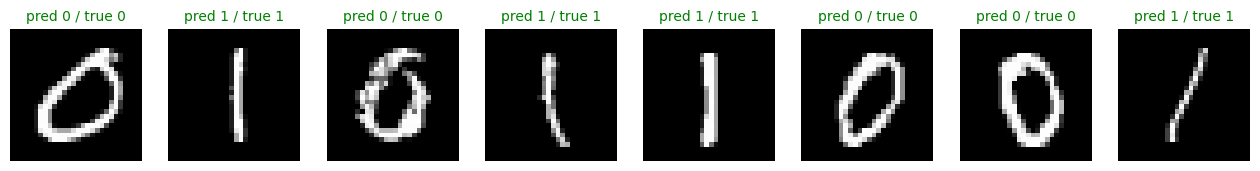

In [ ]:
def show_random_samples(n=8):
    idxs = random.sample(range(len(x_test)), n)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for ax, idx in zip(axes, idxs):
        pred = torch.argmax(predict(network, x_test[idx])).item()
        true = torch.argmax(y_test[idx]).item()
        ax.imshow(x_test[idx][0], cmap="gray"); ax.axis("off")
        ax.set_title(f"pred {pred} / true {true}", color="green" if pred == true else "red", fontsize=10)
    plt.show()

show_random_samples()

### Visualizing layer outputs

What does each layer do to an image? Rows: **input → convolution → ReLU → max-pool**; columns: the 5 filters. Notice how each learned kernel highlights different strokes/edges, how ReLU removes negative responses, and how pooling shrinks the maps while keeping the strongest responses.

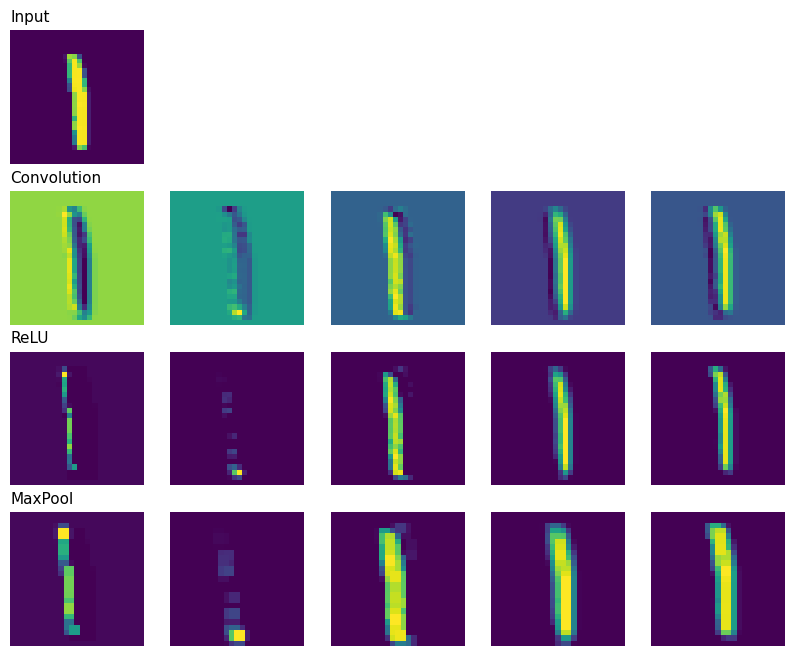

In [ ]:
def show_layer_outputs(network, x):
    stages, out = [("Input", x)], x
    for layer, name in zip(network[:3], ["Convolution", "ReLU", "MaxPool"]):
        out = layer.forward(out)
        stages.append((name, out))

    fig, axes = plt.subplots(len(stages), 5, figsize=(10, 8))
    for r, (name, t) in enumerate(stages):
        for c in range(5):
            ax = axes[r][c]; ax.axis("off")
            if c < t.shape[0]:
                ax.imshow(t[c])
            if c == 0:
                ax.set_title(name, loc="left", fontsize=11)
    plt.show()

show_layer_outputs(network, x_test[random.randint(0, len(x_test) - 1)])

### Layer output shapes

Let's print how the shape changes as an image flows through the network (compare with the diagram above).

In [ ]:
def layer_shape(network, input):
    output = input
    print(f"{'Input':<14}{tuple(output.shape)}")
    for layer in network:
        output = layer.forward(output)
        print(f"{type(layer).__name__:<14}{tuple(output.shape)}")
    return output.argmax().item()

sample = random.randint(0, len(x_test) - 1)
print("True label:", torch.argmax(y_test[sample]).item())
print("Predicted :", layer_shape(network, x_test[sample]))

True label: 0
Input         (1, 28, 28)
Convolutional (5, 26, 26)
ReLU          (5, 26, 26)
MaxPool       (5, 25, 25)
Reshape       (3125, 1)
Dense         (100, 1)
TanH          (100, 1)
Dense         (2, 1)
Softmax       (2, 1)
Predicted : 0


### Wrap-up

- Every layer = `forward` (compute output) + `backward` (turn `dL/dOutput` into `dL/dInput`, update parameters).
- **Convolution backward:** kernel gradient = correlation of input with the output gradient; input gradient = *full convolution* of the output gradient with the kernel.
- **Activation backward:** multiply by `f'(x)`. **MaxPool backward:** route gradient to the winner. **Reshape backward:** reshape back. **Dense backward:** `dW = dY·Xᵀ`, `dX = Wᵀ·dY`.
- A **gradient check** against autograd is the standard way to validate a hand-written backward pass.

## EXERCISE
Write a `Sigmoid` activation class (with `forward` and `backward`) and retrain the network with sigmoid **replacing softmax** in the output layer. (Hint: `sigmoid(x) = 1 / (1 + exp(-x))` and its derivative is `s(x) * (1 - s(x))`; you can derive it with the same `Activation` base class.) Compare the accuracy with the softmax version. Why does binary log-loss now fit the setup even more naturally?

**Other homework (use an AI assistant):**
1. Ask it to turn the forward pipeline into a short "detective story" (one step per layer) and check that every step matches the maths.
2. Ask: *"Why does max pooling have no trainable parameters, and what are the trade-offs versus average pooling or a strided convolution?"*
3. Extend the gradient check to `Dense` and `TanH`.